## 15. Write a python program to add artificial noise (Salt and Pepper, Gaussian) and restore images.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

**Purpose:** Defines a helper to add salt-and-pepper noise to an image.

In [3]:
def salt_pepper_noise(img,amount):
    noisy = img.copy()
    
    total_pixel = img.size
    num_noise = int(total_pixel*amount)
    
    # generate random noise coordinates
    rows = np.random.randint(0,img.shape[0],num_noise)
    cols = np.random.randint(0,img.shape[1],num_noise)
    
    #salt half noises
    noisy[rows[:num_noise//2],cols[:num_noise//2]] = 255
    #pepper half noises
    noisy[rows[num_noise//2:],cols[num_noise//2:]] = 0
    
    return noisy
    

**Purpose:** Defines a helper to add Gaussian noise and clamp values to 8-bit range.

In [9]:
def gaussian_noise(img,mean=0,sigma = 25):
    noise = np.random.normal(mean,sigma,img.shape)
    print(noise.shape)
    noisy = img.astype(np.float32)+noise
    
    noisy[noisy>255] = 255
    noisy[noisy<0] = 0
    return noisy.astype(np.uint8)

**Purpose:** Defines a 3-by-3 averaging filter for noise reduction.

In [6]:
def average_filter(img):
    r,c = img.shape
    result = np.zeros_like(img)
    
    for i in range(1, r-1):
        for j in range(1,c-1):
            region = img[i-1:i+2, j-1:j+2]
            avg = np.mean(region)
            result[i][j] = avg
    return result


**Purpose:** Defines a 3-by-3 median filter for noise reduction.

In [7]:
def median_filter(img):
    r,c = img.shape
    result = np.zeros_like(img)
    
    for i in range(1, r-1):
        for j in range(1,c-1):
            region = img[i-1:i+2, j-1:j+2]
            result[i][j] = np.median(region)
             
    return result

**Purpose:** Adds salt-and-pepper and Gaussian noise, then filters each noisy image.

In [11]:
img = cv2.imread('../cat.jpg',0)

sp_noisy = salt_pepper_noise(img,0.05)
gaussian_noisy = gaussian_noise(img)

sp_restored = median_filter(sp_noisy)
gaussian_restored = average_filter(gaussian_noisy)

(493, 740)


**Purpose:** Compares the noisy images with their filtered results.

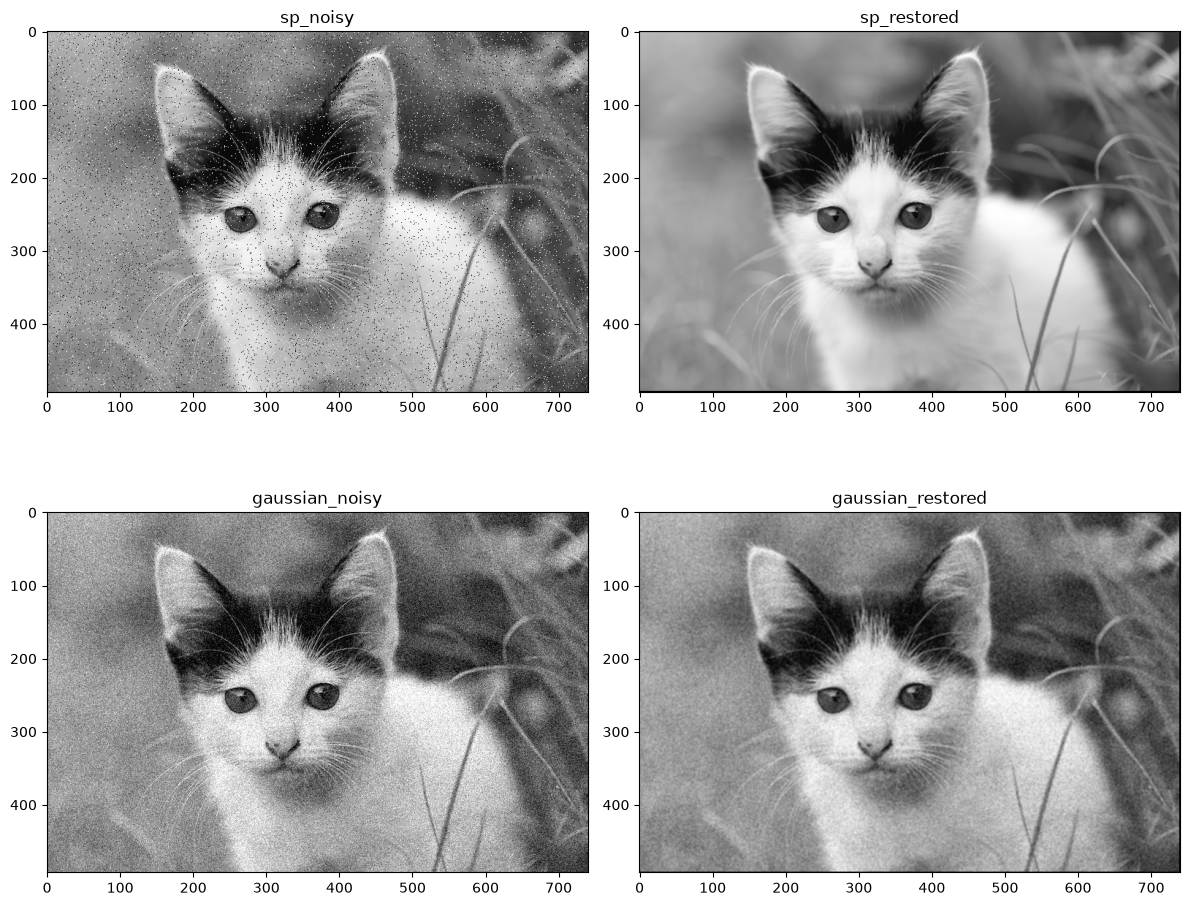

In [23]:
plt.figure(figsize=(12,10))
plt.subplot(2,2,1)
plt.imshow(sp_noisy,cmap='gray')
plt.title('sp_noisy')

plt.subplot(2,2,2)
plt.imshow(sp_restored,cmap='gray')
plt.title('sp_restored')

plt.subplot(2,2,3)
plt.imshow(gaussian_noisy,cmap='gray')
plt.title('gaussian_noisy')

plt.subplot(2,2,4)
plt.imshow(gaussian_restored,cmap='gray')
plt.title('gaussian_restored')

plt.tight_layout()
plt.show()

**Purpose:** This cell is intentionally left blank.